## IML 2026: Introduction to Machine Learning
## Decision Trees, Bagging, and Random Forests — Iris

### Soumik Bhattacharyya, MDE2026005

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, GridSearchCV
)
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, f1_score
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier

RANDOM_STATE = 42
N_SPLITS = 5

iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
class_names = iris.target_names

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class counts:", np.bincount(y_train))
print("Test class counts:", np.bincount(y_test))

Train: (105, 4)  Test: (45, 4)
Train class counts: [35 35 35]
Test class counts: [15 15 15]


## Q1. Gini, entropy, and the best petal-length split

Gini impurity at root:    0.6667
Entropy at root:          1.5850
Best petal-length split:  <= 2.4500 cm
Information gain:         0.9183

DecisionTreeClassifier root:
Feature: petal length (cm)
Threshold: 2.449999988079071
Root criterion: Gini


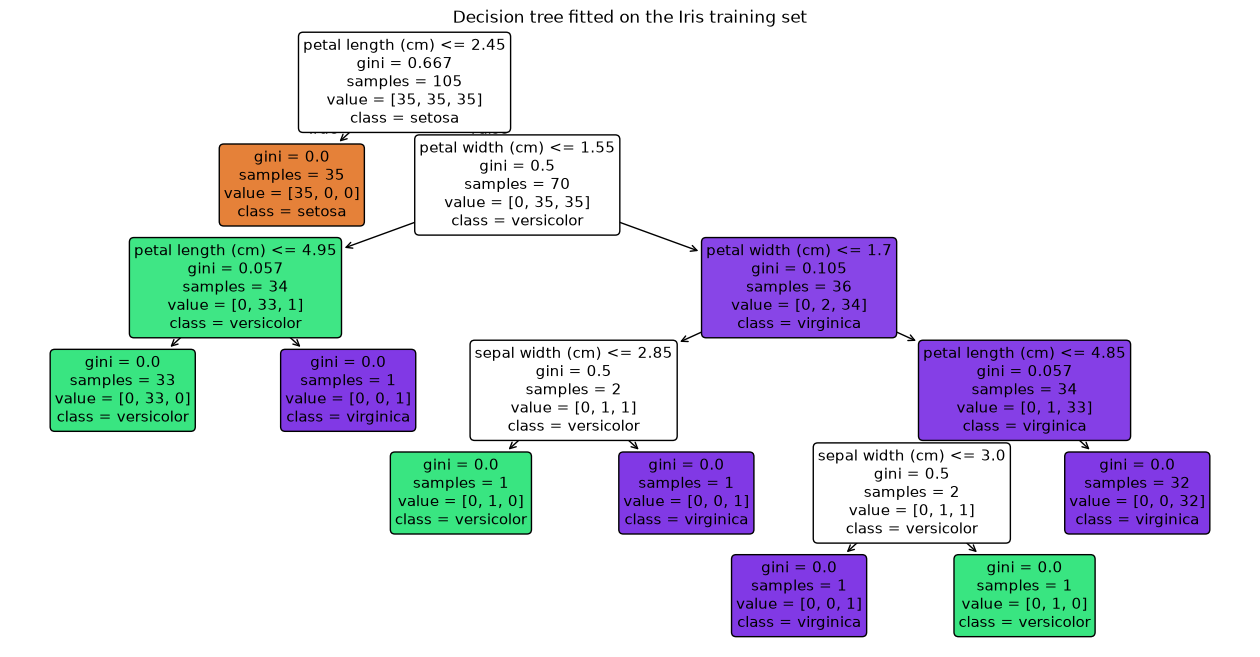

In [2]:
def gini(y):
    """Gini impurity of a one-dimensional class-label array."""
    if len(y) == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / counts.sum()
    return 1.0 - np.sum(probabilities ** 2)


def entropy(y):
    """Shannon entropy (base 2) of a one-dimensional class-label array."""
    if len(y) == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / counts.sum()
    return -np.sum(probabilities * np.log2(probabilities))


def information_gain(y, left_mask, impurity=entropy):
    """Parent impurity minus the size-weighted child impurities."""
    y_left = y[left_mask]
    y_right = y[~left_mask]
    n = len(y)
    if len(y_left) == 0 or len(y_right) == 0:
        return 0.0
    weighted_children = (
        len(y_left) / n * impurity(y_left)
        + len(y_right) / n * impurity(y_right)
    )
    return impurity(y) - weighted_children


# Search thresholds using training data only.
petal_length_index = feature_names.index("petal length (cm)")
x_petal = X_train[:, petal_length_index]
unique_values = np.unique(x_petal)
thresholds = (unique_values[:-1] + unique_values[1:]) / 2

candidate_results = []
for threshold in thresholds:
    left_mask = x_petal <= threshold
    gain = information_gain(y_train, left_mask, impurity=entropy)
    candidate_results.append((gain, threshold))

best_gain, best_threshold = max(candidate_results, key=lambda item: item[0])

print(f"Gini impurity at root:    {gini(y_train):.4f}")
print(f"Entropy at root:          {entropy(y_train):.4f}")
print(f"Best petal-length split:  <= {best_threshold:.4f} cm")
print(f"Information gain:         {best_gain:.4f}")

# Default sklearn tree uses Gini impurity and considers all four features.
root_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
root_tree.fit(X_train, y_train)

root_feature = root_tree.tree_.feature[0]
root_threshold = root_tree.tree_.threshold[0]
print("\nDecisionTreeClassifier root:")
print("Feature:", feature_names[root_feature])
print("Threshold:", root_threshold)
print("Root criterion: Gini")

plt.figure(figsize=(16, 8))
plot_tree(
    root_tree,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    impurity=True
)
plt.title("Decision tree fitted on the Iris training set")
plt.show()

**Observation and concept — impurity:** The custom search finds the best *single-feature petal-length* split under entropy, whereas the sklearn tree chooses the best split across all four features using Gini impurity. Their thresholds need not match: the candidate features and impurity criteria differ. Both criteria quantify class impurity, and a good split produces child nodes that are more class-homogeneous than the parent.

## Q2. Effect of tree depth

,max_depth,train_accuracy,test_accuracy,test_macro_f1
0,1,0.666667,0.666667,0.555556
1,2,0.971429,0.888889,0.888765
2,3,0.980952,0.977778,0.977753
3,5,1.000000,0.933333,0.932660
4,8,1.000000,0.933333,0.932660
5,None,1.000000,0.933333,0.932660


Best depth by 5-fold CV macro-F1: 3
Best mean CV macro-F1: 0.9519


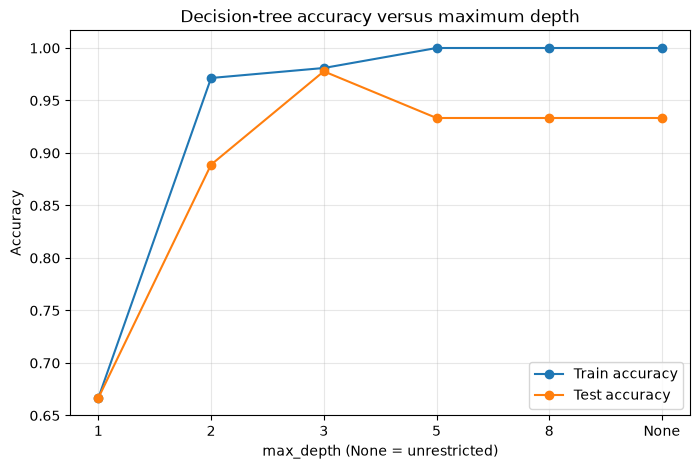

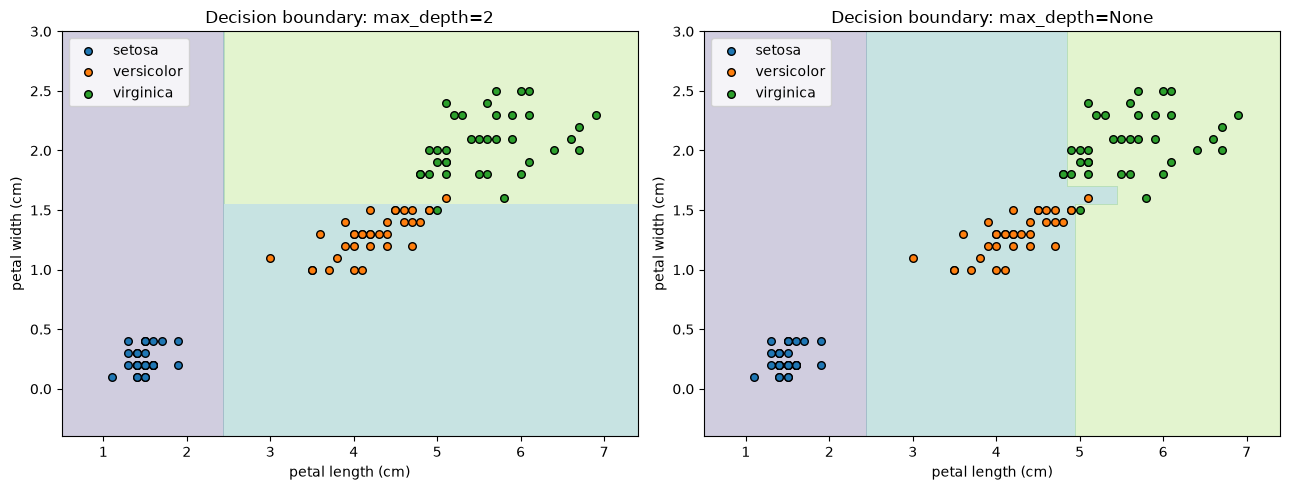

In [8]:
depth_values = [1, 2, 3, 5, 8, None]
depth_results = []

for depth in depth_values:
    model = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    model.fit(X_train, y_train)
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    depth_results.append({
        "max_depth": "None" if depth is None else depth,
        "train_accuracy": accuracy_score(y_train, train_pred),
        "test_accuracy": accuracy_score(y_test, test_pred),
        "test_macro_f1": f1_score(y_test, test_pred, average="macro")
    })

depth_df = pd.DataFrame(depth_results)
display(depth_df)

# Hyperparameter selection is performed using training data only.
depth_search = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid={"max_depth": depth_values},
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1
)
depth_search.fit(X_train, y_train)
print("Best depth by 5-fold CV macro-F1:", depth_search.best_params_["max_depth"])
print("Best mean CV macro-F1:", round(depth_search.best_score_, 4))

# Accuracy versus depth.
plot_df = depth_df.copy()
plot_df["depth_numeric"] = [9 if d == "None" else d for d in plot_df["max_depth"]]
plot_df = plot_df.sort_values("depth_numeric")
labels = ["None" if d == 9 else str(d) for d in plot_df["depth_numeric"]]

plt.figure(figsize=(8, 5))
plt.plot(labels, plot_df["train_accuracy"], marker="o", label="Train accuracy")
plt.plot(labels, plot_df["test_accuracy"], marker="o", label="Test accuracy")
plt.xlabel("max_depth (None = unrestricted)")
plt.ylabel("Accuracy")
plt.title("Decision-tree accuracy versus maximum depth")
# plt.ylim(0.85, 1.02)
plt.grid(alpha=0.3)
plt.legend()
plt.show()

# Two-feature decision boundaries for visualization.
boundary_features = [2, 3]  # petal length and petal width
X_train_2d = X_train[:, boundary_features]
X_test_2d = X_test[:, boundary_features]

def plot_tree_boundary(depth, ax):
    model = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE)
    model.fit(X_train_2d, y_train)

    x_min, x_max = X[:, 2].min() - 0.5, X[:, 2].max() + 0.5
    y_min, y_max = X[:, 3].min() - 0.5, X[:, 3].max() + 0.5
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 400),
        np.linspace(y_min, y_max, 400)
    )
    grid = np.c_[xx.ravel(), yy.ravel()]
    zz = model.predict(grid).reshape(xx.shape)

    ax.contourf(xx, yy, zz, alpha=0.25, levels=np.arange(-0.5, 3.5, 1))
    for class_id, class_name in enumerate(class_names):
        mask = y_train == class_id
        ax.scatter(
            X_train_2d[mask, 0], X_train_2d[mask, 1],
            label=class_name, edgecolor="k", s=30
        )
    ax.set_xlabel(feature_names[2])
    ax.set_ylabel(feature_names[3])
    ax.set_title(f"Decision boundary: max_depth={depth}")
    ax.legend()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_tree_boundary(2, axes[0])
plot_tree_boundary(None, axes[1])
plt.tight_layout()
plt.show()

**Observation and concept — bias and variance:** The tree starts to overfit around max_depth = 3, where training accuracy continues to improve but test accuracy starts decreasing. This indicates increasing variance: deeper trees become increasingly sensitive to individual training observations. Decision trees produce axis-parallel rectangular regions because each split considers one feature at a time. Fully grown trees have high variance because small changes in training data can produce substantially different tree structures.

## Q3. Overfitting, axis-parallel boundaries, and variance


**Answer — bias and variance:** A decision tree splits one feature at a time using rules of the form `feature <= threshold`; each rule creates an axis-aligned cut, so intersections of these cuts form axis-parallel rectangular regions. A fully grown tree can create many small regions and respond strongly to individual training observations, making its predictions sensitive to the particular sample (high variance). Use the depth plot to name the first depth where training performance continues improving while test performance stops improving or declines; that is the observed onset of overfitting for this split.

## Q4. Bagging implemented by hand

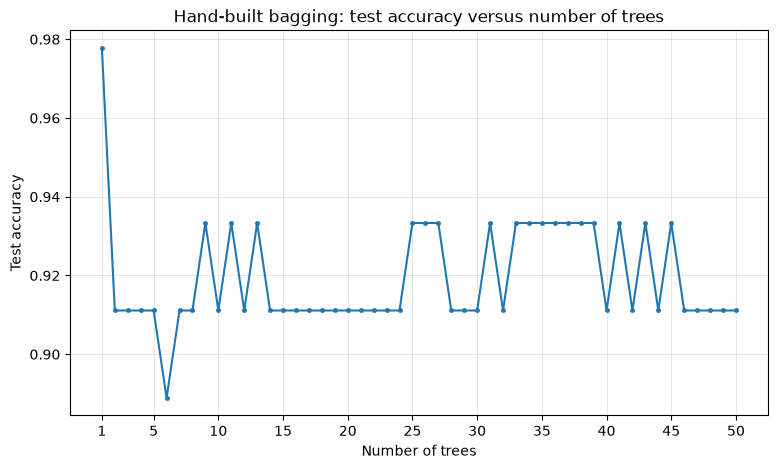

Hand-built bagging test accuracy: 0.9111
Hand-built bagging test macro-F1: 0.9107


In [4]:
rng = np.random.default_rng(RANDOM_STATE)
n_train = len(X_train)
n_trees = 50
bootstrap_trees = []

for tree_number in range(n_trees):
    sample_indices = rng.choice(n_train, size=n_train, replace=True)
    X_boot = X_train[sample_indices]
    y_boot = y_train[sample_indices]

    tree = DecisionTreeClassifier(random_state=RANDOM_STATE + tree_number)
    tree.fit(X_boot, y_boot)
    bootstrap_trees.append(tree)


def majority_vote(prediction_matrix):
    """Return the most frequent class in each row; ties use smallest class label."""
    n_rows = prediction_matrix.shape[0]
    predictions = np.empty(n_rows, dtype=int)
    for row in range(n_rows):
        labels, counts = np.unique(prediction_matrix[row], return_counts=True)
        predictions[row] = labels[np.argmax(counts)]
    return predictions


test_predictions_by_tree = np.column_stack([
    tree.predict(X_test) for tree in bootstrap_trees
])

ensemble_accuracies = []
for n in range(1, n_trees + 1):
    ensemble_prediction = majority_vote(test_predictions_by_tree[:, :n])
    ensemble_accuracies.append(accuracy_score(y_test, ensemble_prediction))

plt.figure(figsize=(9, 5))
plt.plot(range(1, n_trees + 1), ensemble_accuracies, marker=".", markersize=5)
plt.xlabel("Number of trees")
plt.ylabel("Test accuracy")
plt.title("Hand-built bagging: test accuracy versus number of trees")
plt.xticks([1, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50])
plt.grid(alpha=0.3)
plt.show()

hand_bag_pred = majority_vote(test_predictions_by_tree)
print("Hand-built bagging test accuracy:",
      round(accuracy_score(y_test, hand_bag_pred), 4))
print("Hand-built bagging test macro-F1:",
      round(f1_score(y_test, hand_bag_pred, average="macro"), 4))

**Observation and concept — variance reduction:** Individual deep trees can vary substantially because each bootstrap sample contains a different collection of repeated and omitted observations. Majority voting combines these unstable predictions, so the ensemble often becomes more stable as trees are added; the curve may fluctuate, but typically levels off as additional trees provide diminishing benefit. This is bagging: aggregation of many high-variance base learners.

## Q5. Compare hand-built bagging, BaggingClassifier, and RandomForestClassifier

In [6]:
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
    n_estimators=50,
    bootstrap=True,
    oob_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)


forest_model = RandomForestClassifier(
    n_estimators=50,
    max_features="sqrt",
    bootstrap=True,
    oob_score=True,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

bagging_model.fit(X_train, y_train)
forest_model.fit(X_train, y_train)

bagging_pred = bagging_model.predict(X_test)
forest_pred = forest_model.predict(X_test)

comparison = pd.DataFrame([
    {
        "model": "Hand-built bagging",
        "test_accuracy": accuracy_score(y_test, hand_bag_pred),
        "test_macro_f1": f1_score(y_test, hand_bag_pred, average="macro"),
        "OOB_score": np.nan
    },
    {
        "model": "BaggingClassifier",
        "test_accuracy": accuracy_score(y_test, bagging_pred),
        "test_macro_f1": f1_score(y_test, bagging_pred, average="macro"),
        "OOB_score": bagging_model.oob_score_
    },
    {
        "model": 'RandomForestClassifier(max_features="sqrt")',
        "test_accuracy": accuracy_score(y_test, forest_pred),
        "test_macro_f1": f1_score(y_test, forest_pred, average="macro"),
        "OOB_score": forest_model.oob_score_
    }
])
display(comparison)

,model,test_accuracy,test_macro_f1,OOB_score
0,Hand-built bagging,0.911111,0.910714,NaN
1,BaggingClassifier,0.933333,0.933259,0.952381
2,"RandomForestClassifier(max_features=""sqrt"")",0.888889,0.887767,0.952381


**Observation and concept — weak learners / diversity:** Each unrestricted tree is a strong, low-bias but high-variance learner rather than a conventional weak learner; the benefit comes from combining many diverse trees. Bagging creates diversity through bootstrap samples, while a random forest adds feature subsampling at each split, reducing correlation between trees. Less-correlated errors make averaging more effective; OOB scores provide an internal estimate using training cases left out of each tree's bootstrap sample.

## Q6. Why averaging deep trees helps, and what random forests add

**Answer — variance, bias, and OOB fraction:** Averaging many deep trees reduces variance because sample-specific fluctuations tend to cancel when their predictions are aggregated, while systematic errors shared by the trees (bias) are not automatically removed. A random forest adds random feature selection at each split (`max_features="sqrt"` here), which decorrelates trees beyond the diversity created by bootstrap sampling. For a bootstrap sample of size \(n\) drawn with replacement from \(n\) observations, the probability that a particular observation is never selected is \((1-1/n)^n\), which approaches \(e^{-1} \approx 0.368\); thus roughly 36.8% of the training observations are OOB for any one tree.

In [7]:
n = len(X_train)
oob_fraction_theoretical = (1 - 1 / n) ** n
print(f"Theoretical OOB fraction for n={n}: {oob_fraction_theoretical:.4f}")
print(f"Large-n limit (1/e): {np.exp(-1):.4f}")

Theoretical OOB fraction for n=105: 0.3661
Large-n limit (1/e): 0.3679
